<a href="https://colab.research.google.com/github/i11alejo/Proyecto-Ciencias-de-datos/blob/main/Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# 1. IMPORTACIÓN DE LIBRERÍAS DEL PROYECTO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

sns.set_theme(style="whitegrid")
print("Librerías importadas correctamente")

Librerías importadas correctamente


In [5]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("datresearch/training-load-and-performance-dataset")

print("Path to dataset files:", path)

100%|██████████| 511k/511k [00:00<00:00, 82.5MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/datresearch/training-load-and-performance-dataset/versions/1


In [6]:
import os

# 1. Buscar archivo(s) que hay dentro de la carpeta descargada
archivos = os.listdir(path)
print("Archivos encontrados:", archivos)

# 2. Cargar el primer archivo CSV en pandas
archivo_csv = [f for f in archivos if f.endswith('.csv')][0]
ruta_completa = os.path.join(path, archivo_csv)

df = pd.read_csv(ruta_completa)

# 3. Inspección inicial para validar dimensiones y columnas
print(f"\nDataset cargado con éxito: {df.shape[0]} filas y {df.shape[1]} columnas.")
print("\nNombres de las columnas:")
print(df.columns.tolist())

# Mostrar las primeras 5 filas y verificar valores nulos
display(df.head())
print("\nValores nulos por columna:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Archivos encontrados: ['Wushu_Training_Full_Dataset.csv']

Dataset cargado con éxito: 4000 filas y 22 columnas.

Nombres de las columnas:
['Player_ID', 'Resting_HR', 'Training_HR', 'HRV', 'SpO2', 'Sleep_Duration', 'Sleep_Quality', 'Fatigue_Index', 'Movement_Speed', 'Accuracy', 'Reaction_Time', 'Strength_Power', 'Endurance', 'Fatigue_Level', 'Session_Duration', 'Training_Intensity', 'Repetitions', 'Sets', 'Distance_Covered', 'sRPE', 'Performance_Score', 'Optimal_Load_Class']


,Player_ID,Resting_HR,Training_HR,HRV,SpO2,Sleep_Duration,Sleep_Quality,Fatigue_Index,Movement_Speed,Accuracy,...,Endurance,Fatigue_Level,Session_Duration,Training_Intensity,Repetitions,Sets,Distance_Covered,sRPE,Performance_Score,Optimal_Load_Class
0,1,83,162,46.397552,95.777583,4.110700,0.239628,1.000000,5.015063,0.667936,...,130.655779,0.965522,32,Medium,31,4,3714.225526,7.450694,0.550654,Low
1,2,69,131,62.750756,97.815631,6.632624,0.852556,0.762978,1.904436,0.605926,...,79.562265,0.736827,156,Low,16,8,4499.748971,6.161316,0.414754,Medium
2,3,62,157,93.283834,99.994639,5.251673,0.641339,1.000000,4.486123,0.513607,...,181.673322,1.000000,152,High,45,1,3672.636706,8.701570,0.473076,High
3,4,75,120,53.630809,99.922125,4.571610,0.442229,1.000000,1.062102,0.985301,...,226.915315,0.894639,113,High,29,2,3878.982254,10.000000,0.613470,High
4,5,73,162,52.860434,97.954695,8.418793,0.739203,1.000000,5.530574,0.733645,...,184.245520,1.000000,111,Low,46,1,2315.467439,4.228197,0.580956,Medium



Valores nulos por columna:
Series([], dtype: int64)


--- INFORMACIÓN GENERAL DEL DATASET ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Player_ID           4000 non-null   int64  
 1   Resting_HR          4000 non-null   int64  
 2   Training_HR         4000 non-null   int64  
 3   HRV                 4000 non-null   float64
 4   SpO2                4000 non-null   float64
 5   Sleep_Duration      4000 non-null   float64
 6   Sleep_Quality       4000 non-null   float64
 7   Fatigue_Index       4000 non-null   float64
 8   Movement_Speed      4000 non-null   float64
 9   Accuracy            4000 non-null   float64
 10  Reaction_Time       4000 non-null   float64
 11  Strength_Power      4000 non-null   float64
 12  Endurance           4000 non-null   float64
 13  Fatigue_Level       4000 non-null   float64
 14  Session_Duration    4000 non-null   int64  
 15  Training_Intens

,Player_ID,Resting_HR,Training_HR,HRV,SpO2,Sleep_Duration,Sleep_Quality,Fatigue_Index,Movement_Speed,Accuracy,Reaction_Time,Strength_Power,Endurance,Fatigue_Level,Session_Duration,Repetitions,Sets,Distance_Covered,sRPE,Performance_Score
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,2000.500000,72.263750,152.123000,70.184278,96.019073,6.465629,0.712031,0.930884,5.492073,0.747251,0.374534,278.044332,165.062226,0.918252,99.738250,27.154750,4.979000,2543.049499,6.876124,0.617822
std,1154.844867,10.109858,25.311648,28.826573,2.303850,1.435976,0.182202,0.111272,2.579812,0.144377,0.130045,130.598458,77.589007,0.111109,46.362092,13.022642,2.603892,1419.456827,2.477060,0.100769
min,1.000000,55.000000,95.000000,20.018520,92.000949,4.000046,0.177207,0.421903,1.000921,0.500083,0.150091,50.041971,30.196416,0.390266,20.000000,5.000000,1.000000,100.564035,1.000000,0.314106
25%,1000.750000,64.000000,132.000000,46.119102,94.030724,5.223765,0.571852,0.889824,3.323986,0.621855,0.263827,165.526256,97.264188,0.881514,59.000000,16.000000,3.000000,1299.877835,4.640404,0.546427
50%,2000.500000,72.500000,152.000000,70.221844,96.053886,6.448610,0.714970,1.000000,5.481523,0.748067,0.372289,279.003655,165.240250,0.965359,101.000000,27.000000,5.000000,2546.954314,6.988325,0.615713
75%,3000.250000,81.000000,172.000000,94.963780,98.000649,7.685556,0.858586,1.000000,7.720830,0.871698,0.487982,393.498582,231.516169,1.000000,140.000000,38.000000,7.000000,3783.497955,9.449524,0.686791
max,4000.000000,89.000000,208.000000,119.974127,99.999141,8.998474,1.000000,1.000000,9.998554,0.999950,0.599743,499.908701,299.948423,1.000000,179.000000,49.000000,9.000000,4998.415579,10.000000,0.937448


/tmp/ipykernel_1420/2692666427.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Optimal_Load_Class', palette='Set2', order=['Low', 'Medium', 'High'])


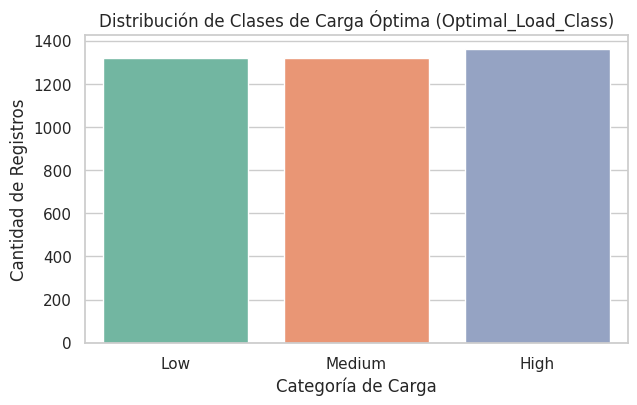

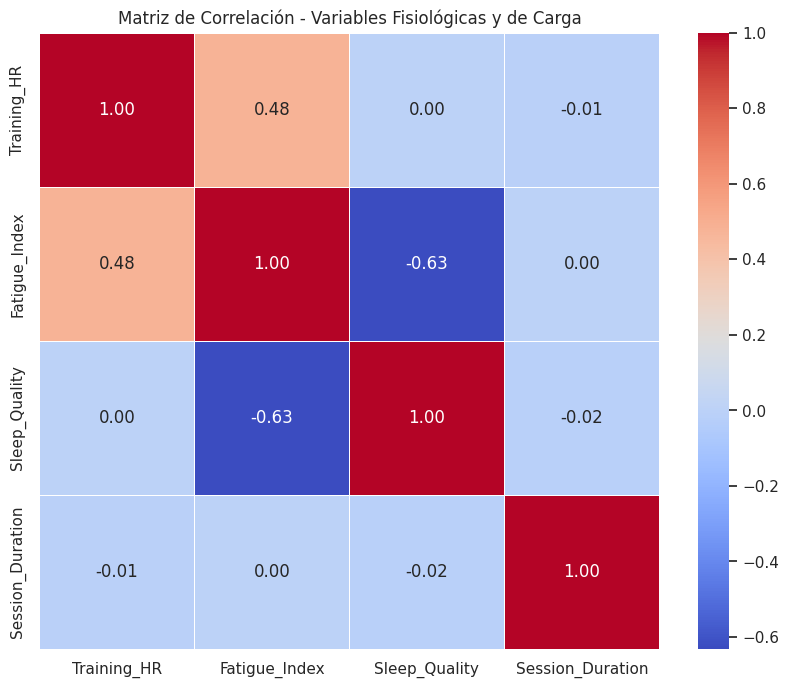

In [7]:
# 3. ANÁLISIS EXPLORATORIO DE DATOS (EDA)

print("--- INFORMACIÓN GENERAL DEL DATASET ---")
print(df.info())

print("\n--- RESUMEN ESTADÍSTICO ---")
display(df.describe())

# 1. Gráfico de distribución de la Variable Objetivo (Optimal_Load_Class)
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Optimal_Load_Class', palette='Set2', order=['Low', 'Medium', 'High'])
plt.title('Distribución de Clases de Carga Óptima (Optimal_Load_Class)')
plt.xlabel('Categoría de Carga')
plt.ylabel('Cantidad de Registros')
plt.show()

# 2. Matriz de Correlación entre variables numéricas clave
plt.figure(figsize=(10, 8))
# Seleccionamos algunas variables numéricas representativas del dataset
columnas_numericas = ['Training_Load', 'Session_RPE', 'Training_HR', 'Fatigue_Index', 'Sleep_Quality', 'Session_Duration']
# Validamos que las columnas existan en el df actual
cols_disponibles = [col for col in columnas_numericas if col in df.columns]

matriz_corr = df[cols_disponibles].corr()
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Matriz de Correlación - Variables Fisiológicas y de Carga')
plt.show()